# 03 · Archetype Discovery (descriptive)

**Status from EXP-04:** no k passed the pre-registered selection rule. The clusterings below are **descriptive partitions**, not validated archetypes.

- k = 2: the only stable role split (bootstrap ARI 0.756)
- k = 5: the near-miss (ARI 0.591 vs 0.6 cutoff)

Setup: fully evolved Pokémon (568), relative stats (stat / BST).

In [11]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

from src.features.preprocessing import STAT_COLS, load_pokemon, make_features, select_subset
from src.models.clustering import assignment_margins, cluster_profiles, fit_kmeans

sns.set_theme(style="whitegrid")
data = select_subset(load_pokemon(), "fully_evolved")
X, _ = make_features(data, "relative")
print(X.shape)

(568, 6)


## 1. Cluster profiles

Centroid values are **shares of total stats** (0.20 = 20%). An even spread would be 1/6 ≈ 0.167 for every stat.

`borderline_share` = fraction of members almost halfway to another cluster (margin < 10%). High values explain low stability.

In [12]:
models, profiles = {}, {}
for k in (2, 5):
    models[k] = fit_kmeans(X, k)
    profiles[k] = cluster_profiles(data, X, models[k])
    print(f"\n===== k = {k} =====")
    display(profiles[k].round(3))


===== k = 2 =====


,cluster,size,share,mean_bst,borderline_share,hp,attack,defense,sp_attack,sp_defense,speed,typical_members
0,0,345,0.607,513.788,0.125,0.158,0.166,0.145,0.187,0.166,0.178,"Golduck, Charizard, Typhlosion, Hydreigon, Zapdos"
1,1,223,0.393,505.040,0.126,0.172,0.207,0.206,0.130,0.167,0.119,"Torterra, Poliwrath, Chesnaught, Iron Thorns, ..."



===== k = 5 =====


,cluster,size,share,mean_bst,borderline_share,hp,attack,defense,sp_attack,sp_defense,speed,typical_members
0,0,59,0.104,494.797,0.186,0.139,0.176,0.265,0.133,0.204,0.084,"Marowak, Spidops, Eiscue, Bronzong, Runerigus"
1,1,113,0.199,498.823,0.124,0.145,0.183,0.133,0.174,0.139,0.227,"Zeraora, Cyclizar, Froslass, Grafaiai, Emolga"
2,2,46,0.081,497.891,0.152,0.266,0.169,0.150,0.154,0.160,0.101,"Lapras, Dudunsparce, Whiscash, Amoonguss, Aurorus"
3,3,184,0.324,526.179,0.130,0.155,0.147,0.155,0.203,0.186,0.153,"Venusaur, Mr. Rime, Ludicolo, Iron Crown, Heatran"
4,4,166,0.292,509.645,0.120,0.166,0.227,0.178,0.130,0.150,0.149,"Regigigas, Mabosstiff, Mightyena, Overqwil, Ir..."


## 2. How each cluster differs from the average Pokémon

Bars show centroid share minus the overall average share, in percentage points. Positive = this group puts more of its stat budget there than typical.

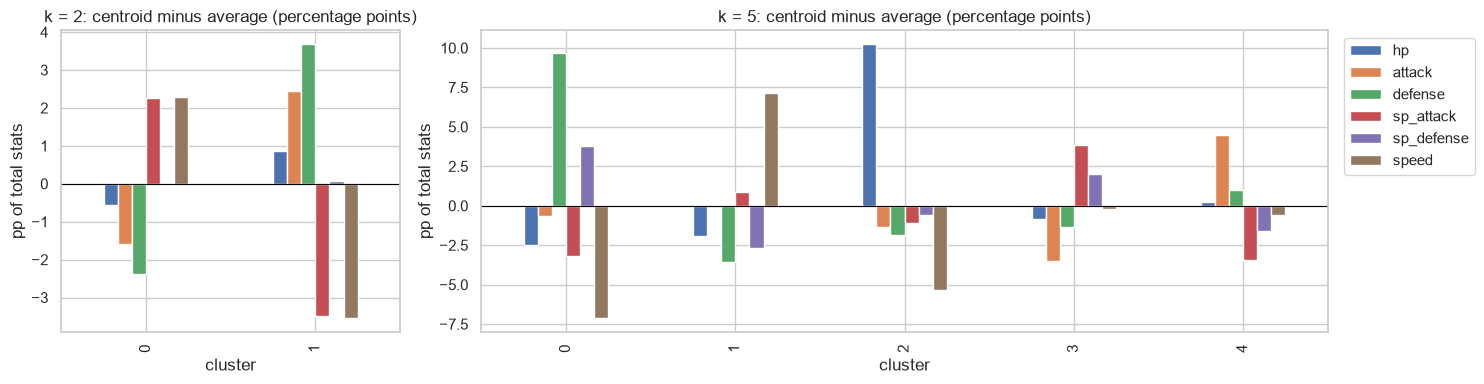

In [13]:
overall = X.mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 5]})
for ax, k in zip(axes, (2, 5)):
    diff = (profiles[k].set_index("cluster")[STAT_COLS] - overall) * 100
    diff.plot.bar(ax=ax, legend=(k == 5))
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"k = {k}: centroid minus average (percentage points)")
    ax.set_ylabel("pp of total stats")
if axes[1].get_legend():
    axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

## 3. PCA: a 2D picture of 6D data

PCA finds new axes (principal components) that are mixes of the original stats, ordered by how much of the spread they capture. We plot the first two.

- **Clustering was done on all 6 features.** PCA is only for viewing.
- Points that overlap in 2D may be far apart in 6D, and vice versa. Check the explained variance: whatever the first two components miss is invisible in the plot.
- Relative stats sum to 1, so one direction has zero spread: the 6th component should explain ~0%.

In [14]:
pca = PCA(random_state=42).fit(X)
print("Explained variance by component:", (pca.explained_variance_ratio_ * 100).round(1), "%")
print(f"First two components together: {pca.explained_variance_ratio_[:2].sum():.0%}")

loadings = pd.DataFrame(pca.components_[:2].T, index=STAT_COLS, columns=["PC1", "PC2"]).round(2)
print("\nLoadings (how much each stat feeds each axis):")
display(loadings)

Explained variance by component: [33.8 26.3 18.4 13.3  8.2  0. ] %
First two components together: 60%

Loadings (how much each stat feeds each axis):


,PC1,PC2
hp,-0.09,0.13
attack,-0.14,0.67
defense,-0.61,-0.05
sp_attack,0.36,-0.46
sp_defense,-0.18,-0.51
speed,0.66,0.23


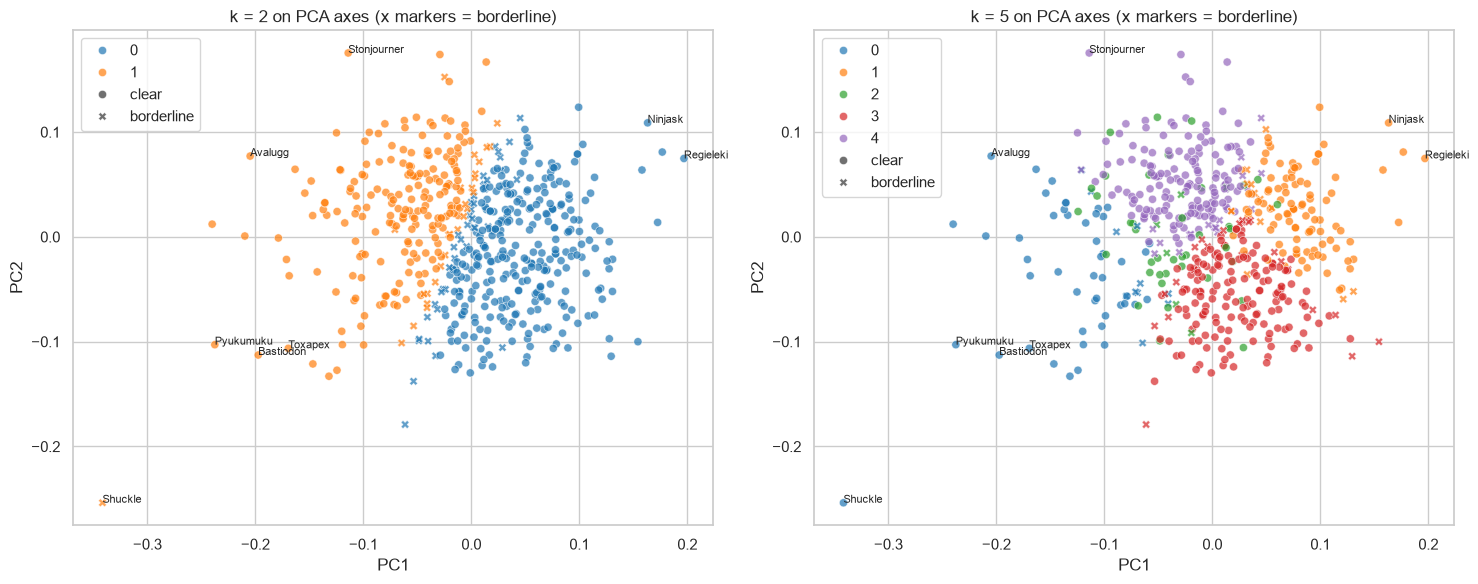

In [15]:
coords = pca.transform(X)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, k in zip(axes, (2, 5)):
    m = assignment_margins(X, models[k])
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=m["cluster"].to_numpy(), palette="tab10",
                    style=m["borderline"].map({True: "borderline", False: "clear"}).to_numpy(),
                    alpha=0.7, s=35, ax=ax)
    ax.set_title(f"k = {k} on PCA axes (x markers = borderline)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

# label a few extreme Pokémon so the axes are easy to read
for i in np.argsort(np.abs(coords).sum(axis=1))[-8:]:
    for ax in axes:
        ax.annotate(data["name"].iloc[i], coords[i], fontsize=8)
plt.tight_layout()

### k = 5: What each group looks like

- **Cluster 0 (Walls):** Defensive Pokémon with high Defense (26.5%) and very low Speed (8.4%). These Pokémon prioritize taking hits over moving quickly.
- **Cluster 1 (Fast attackers):** Pokémon with high Speed (22.7%). They prioritize moving quickly and generally have more offensive stat distributions.
- **Cluster 2 (HP tanks):** Pokémon with a high HP share (26.6%). They rely on having large amounts of health to survive attacks.
- **Cluster 3 (Special attackers):** Pokémon with relatively high Special Attack (20.3%). They are more focused on special damage.
- **Cluster 4 (Physical attackers):** Pokémon with high Attack (22.7%). They are more focused on physical damage.

### k = 2: Physical vs. Special

The k = 2 split is not simply physical versus special. It is better described as physical/bulky versus fast/special. One group has higher Attack (20.7%) and Defense (20.6%), but lower Speed (11.9%). The other group has a faster and more special-oriented stat distribution.

### PCA findings

PCA helps visualize the main patterns in the six-dimensional relative stat data.

- **PC1 explains 34% of the variance.** It contrasts Speed (+0.66) with Defense (-0.61), representing a fast-and-frail versus slow-and-bulky tradeoff.
- **PC2 explains 26% of the variance.** It contrasts Attack (+0.67) with Special Attack and Special Defense (-0.46 and -0.51), representing a physical versus special-oriented tradeoff.
- Together, the first two components explain 60% of the variance. This means 40% of the variation is not visible in the two-dimensional scatter plot.
- The sixth component explains approximately 0% because relative stats always sum to 1, creating a mathematical dependency between the six features.

These PCA findings support patterns also observed in EDA. For example, Defense and Speed have a correlation of -0.51, while Attack and Special Defense have a correlation of -0.55. Two different methods reveal similar stat tradeoffs.

### Why the groups may have been unstable

The k = 5 clustering had a bootstrap ARI of 0.591, slightly below the required 0.6 cutoff. This means the clustering did not meet the stability requirement.

One possible explanation is that the smaller clusters have more borderline members. Walls make up approximately 10% of Pokémon, with 18.6% of members classified as borderline. HP tanks make up approximately 8%, with 15.2% borderline. The other clusters have borderline shares around 12–13%.

My hypothesis is that these smaller groups contribute more to instability because their members may move between clusters when the data is resampled. However, we have not directly measured which clusters are switching, so this remains a hypothesis rather than a confirmed explanation.

Overall, k = 2 is more stable (ARI 0.756), while k = 5 provides more detailed stat-based descriptions but does not meet the stability requirement. Neither should be treated as a set of fully validated archetypes.